# Practical 10 – Classification Before and After PCA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
raw = load_wine(as_frame=True)


In [2]:
X = raw.data
y = raw.target
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


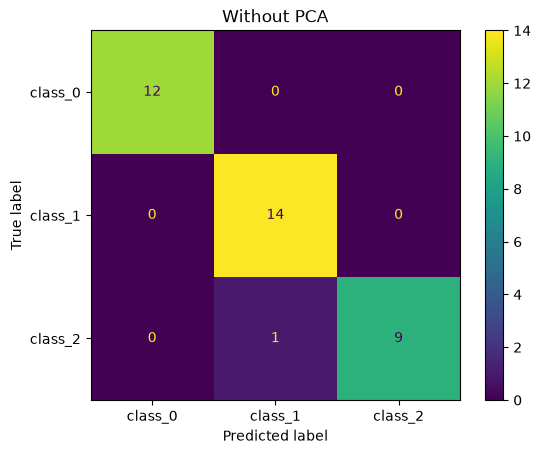

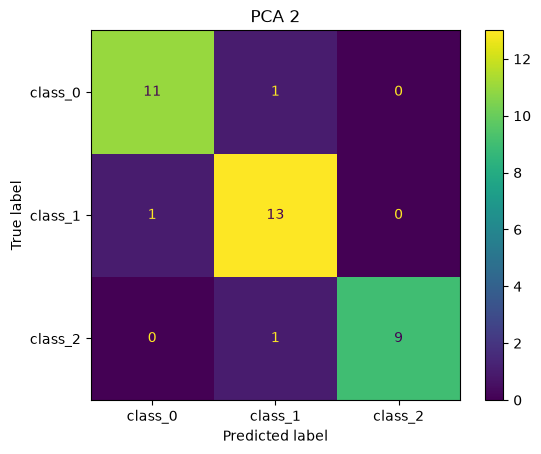

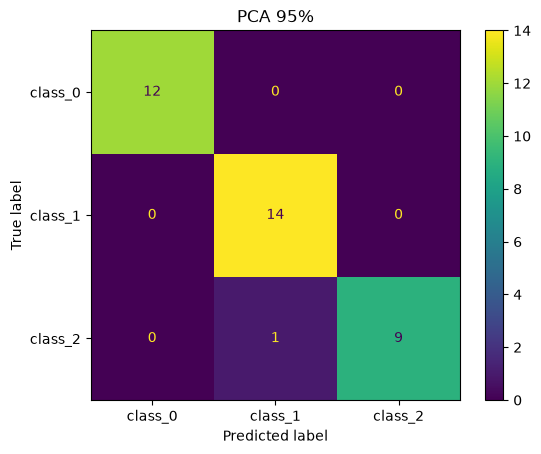

In [3]:
models = {'Without PCA': Pipeline([('scale', StandardScaler()), ('clf', LogisticRegression(max_iter=2000))]), 'PCA 2': Pipeline([('scale', StandardScaler()), ('pca', PCA(n_components=2)), ('clf', LogisticRegression(max_iter=2000))]), 'PCA 95%': Pipeline([('scale', StandardScaler()), ('pca', PCA(n_components=0.95)), ('clf', LogisticRegression(max_iter=2000))])}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    n = model.named_steps['pca'].n_components_ if 'pca' in model.named_steps else 13
    rows.append({'Model': name, 'Features': n, 'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred, average='macro'), 'Recall': recall_score(y_test, pred, average='macro'), 'F1': f1_score(y_test, pred, average='macro')})
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=raw.target_names)
    plt.title(name)
    plt.show()


         Model  Features  Accuracy  Precision  Recall      F1
0  Without PCA        13    0.9722     0.9778  0.9667  0.9710
1        PCA 2         2    0.9167     0.9278  0.9151  0.9202
2      PCA 95%        10    0.9722     0.9778  0.9667  0.9710


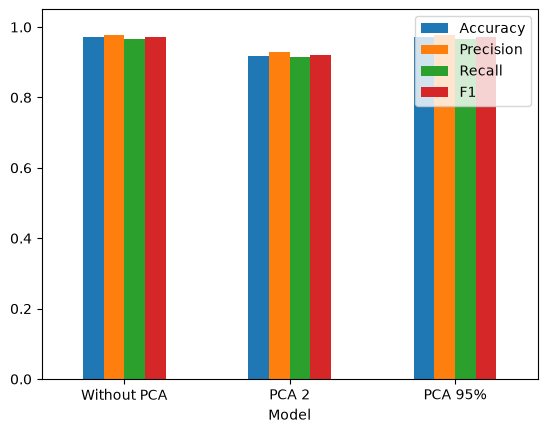

In [4]:
result = pd.DataFrame(rows)
print(result.round(4))
result.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1']].plot.bar(rot=0, ylim=(0, 1.05))
plt.show()
result.to_csv('pca_classification_comparison.csv', index=False)
